## Actividad individual


### Alumno: Anai Lael Barrera Magaña

Objetivo: 
Desarrollar un modelo que permita predecir si un cliente abandonará la empresa de telecom.
Se trata de  un problema de clasificacion binaria, ya que hay dos posibles resultados:
- Yes: el cliente abandonó la empresa
- No: el cliente NO abandonó la empresa

### Instalacion de librerias

### Importar

In [36]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Leer dataset y mostrar las primeras 5 filas

In [37]:
path = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(path)
df.head()



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Análisis exploratorio (EDA)

1.- Estadisticas descriptivas de las variables numericas

In [38]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


SeniorCitizen: variable binaria 0 no es adulto mayor, 1 es adulto mayor
tenure: antiguedad del empleado en meses
MonthlyCharges: paga mensual

2.- Distribución de las variables categóricas

In [39]:
#frecuencia absoluta
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

5174 empleados permanecieron en la empresa, 1869 abandonaron

In [40]:
#frecuencia relativa
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

3.- Visualización de los datos mediante gráficas

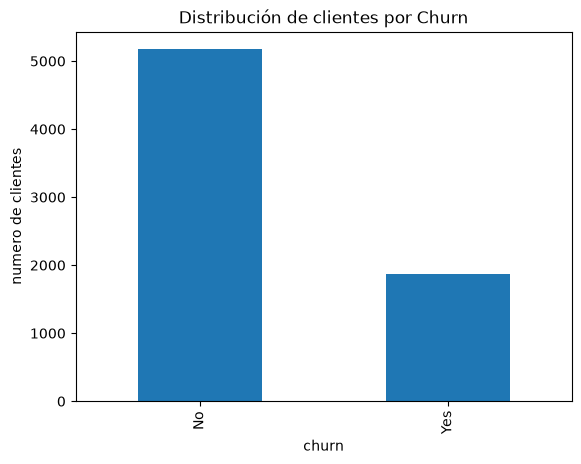

In [41]:
conteo = df["Churn"].value_counts()

conteo.plot(kind="bar")
plt.title("Distribución de clientes por Churn")
plt.xlabel("churn")
plt.ylabel("numero de clientes")
plt.show()


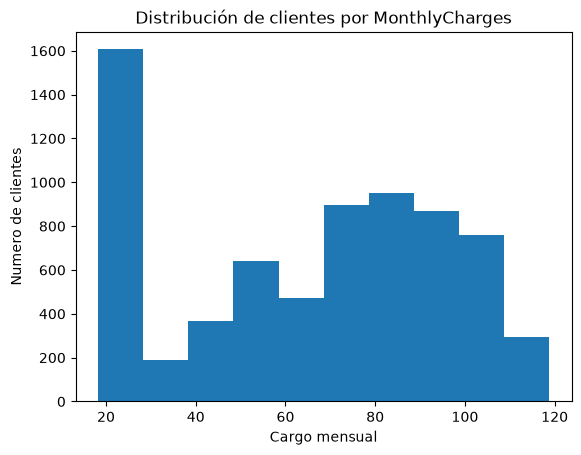

In [42]:
plt.hist(df["MonthlyCharges"],bins=10)
plt.title("Distribución de clientes por MonthlyCharges")
plt.xlabel("Cargo mensual")
plt.ylabel("Numero de clientes")
plt.show()

4.- Análisis de las relaciones entre las variables y *churn*

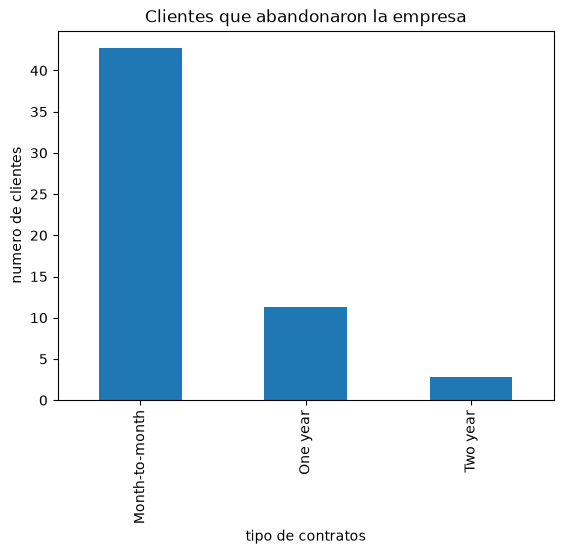

In [43]:
tasas = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100


tasas["Yes"].plot(kind="bar")
plt.title("Clientes que abandonaron la empresa")
plt.xlabel("tipo de contratos")
plt.ylabel("numero de clientes")
plt.show()

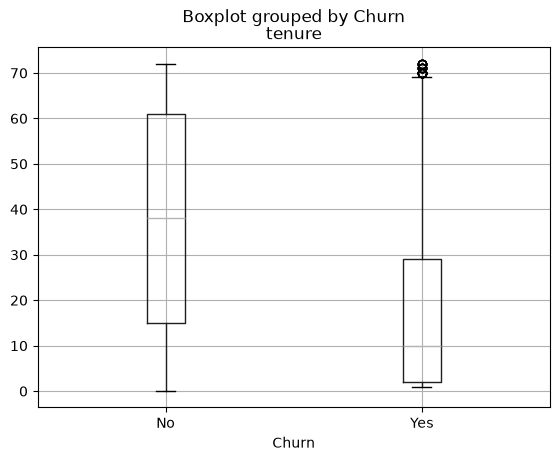

In [44]:
df.boxplot(column="tenure", by="Churn")
plt.show()

Los clientes que permanecieron en la empresa tienen una antiguedad mediana mayor que los que la abandonaron

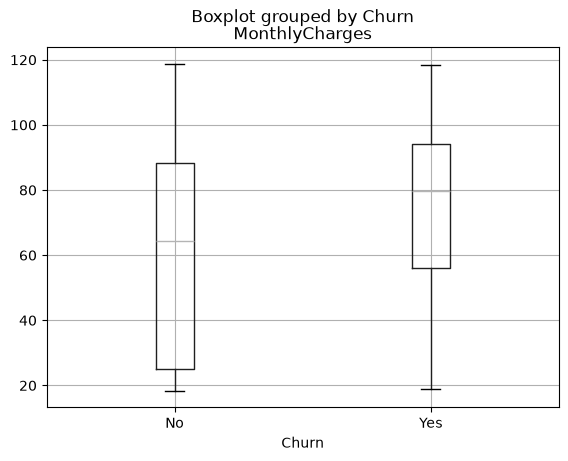

In [45]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.show()

Los clientes que abandonaron la empresa tienen una mediada de cargos mensuales mayor que los que permanecieron

Conclusiones de EDA
Del total de 7,043 registros, el 26.54 % corresponde a clientes que abandonaron la empresa, mientras que el 73.46 % permaneció, lo que indica un desbalance entre las dos clases.
Se observó que los clientes con contratos mes por mes presentan una mayor tasa de abandono (42.71 %), en comparación con aquellos que tienen contratos de uno o dos años. 
Se identificó que los clientes que abandonaron la empresa tienden a tener una menor antigüedad y una mediana de cargos mensuales más alta que quienes permanecieron.
Estos resultados sugieren que el tipo de contrato, la antigüedad y los cargos mensuales podrían ser variables relevantes para el entrenamiento del modelo, ya que presentan diferencias entre los clientes que abandonaron la empresa y los que permanecieron. Aunque estas relaciones no implican necesariamente que dichas características sean las causas del abandono. Será necesario comprobar su utilidad durante el entrenamiento y la evaluación del modelo.


# Limpieza de datos

In [46]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [47]:
df.duplicated().sum()

np.int64(0)

0 filas enteras identicas

Aunque inicialmente no se detectaron valores faltantes mediante isna(), se observó que desde un inicio TotalCharges estaba almacenada como object a pesar de representar una variable $ numerica. Se revisó la columna y se identificaron 11 valores compuestos únicamente por espacios en blanco, los cuales Pandas no reconocía como valores nulos.

In [48]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [49]:
df.loc[
    df["TotalCharges"].str.strip().eq(""),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


TotalCharges aparecen vacios por que los clientes tienen antiguedad de 0 meses, por lo que se va a decir reemplezarlos por 0 ya que todavia no acumulan cargos totales

In [50]:
#reemplazo los vacios por 0, parseo a numerico
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])
df["TotalCharges"].dtype

dtype('float64')

In [51]:
columnas_numericas = df.select_dtypes(include=["int64", "float64"]).columns
columnas_categoricas = df.select_dtypes(include=["object"]).columns
print("Numericas:", columnas_numericas)
print("\n\n")
print("Categoricas:", columnas_categoricas)

Numericas: Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')



Categoricas: Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')


/tmp/ipykernel_9176/3987520569.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df.select_dtypes(include=["object"]).columns


customerID no es una característica numérica ni categórica útil para aprender patrones: es un identificador.

Churn es categórica binaria, va a ser target(y)

seniorcitizen no requiere corecion, aunque es entero sus valores 0 y 1 representan una variable categorica

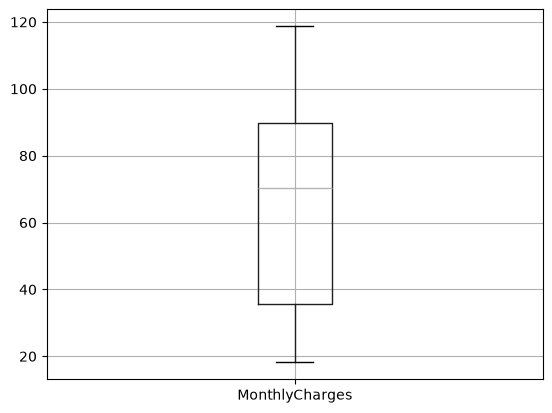

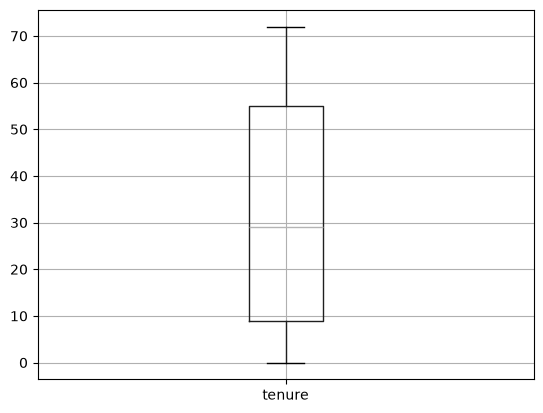

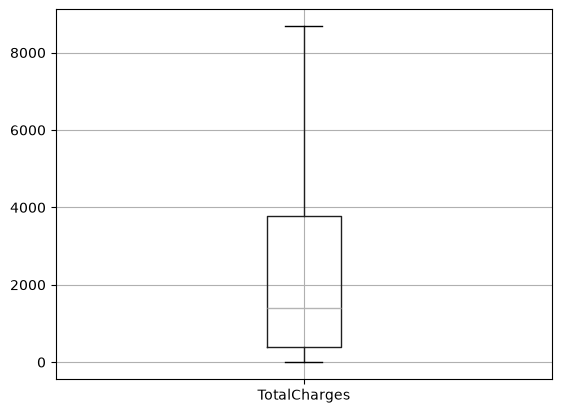

In [52]:
df.boxplot(column="MonthlyCharges")
plt.show()
df.boxplot(column="tenure")
plt.show()
df.boxplot(column="TotalCharges")
plt.show()

In [53]:
for columna in ["tenure", "MonthlyCharges", "TotalCharges"]:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    print(columna, ":", len(outliers), "outliers")


tenure : 0 outliers
MonthlyCharges : 0 outliers
TotalCharges : 0 outliers


No se identificaron valores fuera de los limites establecidos por 1.5 veces el IQR por lo que no fue necesario eliminar/modifcar registros por valores atípicos

In [54]:
df["customerID"].duplicated().sum()

np.int64(0)

no se identificaron customerID duplicados, por lo que cada registro corresponde a un cliente unico

Durante la limpieza se verificaron valores faltantes, registros duplicados, tipos de datos incorrectos y valores atípicos.
Isna() no detectó valores nulos y tampoco se encontraron filas duplicadas ni identificadores customerID repetidos pero al revisar los tipos de datos se observó que TotalCharges, pese a representar una cantidad numérica, estaba almacenada como object. Al analizarla se identificaron 11 registros con espacios en blanco. Estos casos correspondían a clientes con tenure = 0 y se sustituyeron dichos valores por 0 para convertir la variable a float.

# Modelo base y evaluación 

In [55]:
y = df["Churn"]
x = df.drop(columns=["Churn", "customerID"])
x = pd.get_dummies(x, drop_first=True)

print(x.shape)
print(y.shape)

(7043, 30)
(7043,)


In [56]:
x.columns
x.select_dtypes(include=["object"]).columns

Index([], dtype='str')

In [57]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [58]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 30)
(1409, 30)
(5634,)
(1409,)


In [59]:
modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])
modelo.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['SeniorCitizen','tenure','MonthlyCharges',..., 'PaymentMethod_Credit card (automatic)','PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [60]:
y_pred = modelo.predict(x_test)
print("Predicciones:", y_pred[:10])
print("Valores reales:", y_test.iloc[:10].values)

Predicciones: ['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']
Valores reales: <ArrowStringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [61]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_test, y_pred)
print(matriz)

[[925 110]
 [162 212]]


La matriz de confusión mostró que el modelo identificó correctamente 212 clientes que abandonaron, pero no logró detectar 162 casos de abandono. El modelo funciona adecuadamente como punto de referencia inicial, aunque sería necesario mejorar principalmente su capacidad para identificar clientes con riesgo de abandono.

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("Accuracy:", accuracy*100)
print("Precision:", precision*100)
print("Recall:", recall*100)
print("F1:", f1*100)

Accuracy: 80.69552874378992
Precision: 65.83850931677019
Recall: 56.68449197860963
F1: 60.91954022988506


Se entrenó un modelo de Regresión Logística como baseline para predecir el abandono de clientes. 
El modelo obtuvo una exactitud de aproximadamente 80.69 %, superando la proporción de la clase mayoritaria del dataset pero debido al desbalance existente entre clientes que permanecen y clientes que abandonan, la exactitud por sí sola no es suficiente para evaluar su desempeño.
Para la clase "Yes" correspondiente a clientes que abandonan la empresa, el modelo obtuvo una precision de 65.83 %, un recall de 56.68 % y un F1-score de 60.91%. 



# Registro en MLFlow 

In [63]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:////home/anaim/mlops/mlflow.db")

mlflow.set_experiment("Telco_Churn_Baseline")

<Experiment: artifact_location='/home/anaim/mlops/TC5061_Experimentacion_MLFlow_BarreraAnai/notebooks/mlruns/2', creation_time=1791770846488, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791770846488, lifecycle_stage='active', name='Telco_Churn_Baseline', tags={}, trace_location=None, workspace='default'>

In [64]:
with mlflow.start_run():

    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("max_iter", 1000)

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision_yes", precision)
    mlflow.log_metric("recall_yes", recall)
    mlflow.log_metric("f1_yes", f1)

print("modelo v1.0 registrado")

modelo v1.0 registrado


In [65]:
print("Tracking URI:", mlflow.get_tracking_uri())

for exp in mlflow.search_experiments():
    print(exp.experiment_id, exp.name)

Tracking URI: sqlite:////home/anaim/mlops/mlflow.db
2 Telco_Churn_Baseline
1 Telco_Churn_Comparacion
0 Default


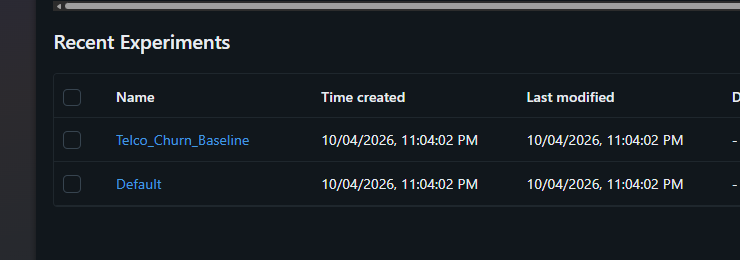

# Reflexión sobre MLOps 

Con esta actividades realicé las principales etapas de un flujo básico de Machine Learning, desde la exploración y limpieza de los datos hasta el entrenamiento, evaluación y registro del modelo. Durante el proceso se observó que obtener un modelo funcional no es suficiente, ya que también es necesario mantener trazabilidad sobre los datos utilizados, las transformaciones realizadas, los parámetros del modelo y las métricas obtenidas (MlFlow).
Aplicando prácticas de MLOps, mejoraría este flujo mediante pipelines reproducibles que automaticen la limpieza, transformación, entrenamiento y evaluación. También utilizaría versionamiento para los datasets y el código, además de MLflow para comparar diferentes ejecuciones y versiones del modelo. Otro aspecto importante sería incorporar validaciones automáticas antes de aprobar un modelo y monitorear su comportamiento una vez desplegado, especialmente para detectar cambios en los datos o disminuciones en su desempeño.
En mi área profesional, estos aprendizajes se relacionan directamente con el gobierno de soluciones de inteligencia artificial. No basta con desarrollar un modelo; también es necesario demostrar cómo fue construido, qué datos utilizó, cómo fue evaluado y qué controles se aplicaron durante su ciclo de vida. La trazabilidad, reproducibilidad, evaluación y monitoreo son elementos necesarios tanto para MLOps como para un adecuado gobierno de IA.